<a href="https://colab.research.google.com/github/LalithaSreya/de-telecom-network-performance-analytics/blob/main/customer_segmentation_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

data = {
    'Customer_ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Annual_Income': [15, 18, 20, 22, 25, 70, 75, 80, 85, 90],
    'Spending_Score': [20, 25, 30, 35, 40, 75, 80, 85, 90, 95]
}

df = pd.DataFrame(data)

print(df)

   Customer_ID  Annual_Income  Spending_Score
0            1             15              20
1            2             18              25
2            3             20              30
3            4             22              35
4            5             25              40
5            6             70              75
6            7             75              80
7            8             80              85
8            9             85              90
9           10             90              95


In [2]:
print(df.head())
print(df.shape)
print(df.describe())

   Customer_ID  Annual_Income  Spending_Score
0            1             15              20
1            2             18              25
2            3             20              30
3            4             22              35
4            5             25              40
(10, 3)
       Customer_ID  Annual_Income  Spending_Score
count     10.00000      10.000000       10.000000
mean       5.50000      50.000000       57.500000
std        3.02765      32.159326       29.930475
min        1.00000      15.000000       20.000000
25%        3.25000      20.500000       31.250000
50%        5.50000      47.500000       57.500000
75%        7.75000      78.750000       83.750000
max       10.00000      90.000000       95.000000


In [3]:
X = df[['Annual_Income', 'Spending_Score']]

print(X.head())

   Annual_Income  Spending_Score
0             15              20
1             18              25
2             20              30
3             22              35
4             25              40


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.1472019  -1.32067636]
 [-1.04887031 -1.14458618]
 [-0.98331591 -0.968496  ]
 [-0.91776152 -0.79240582]
 [-0.81942993 -0.61631563]]


In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

df['Cluster'] = kmeans.labels_

print(df)

   Customer_ID  Annual_Income  Spending_Score  Cluster
0            1             15              20        0
1            2             18              25        0
2            3             20              30        0
3            4             22              35        4
4            5             25              40        4
5            6             70              75        2
6            7             75              80        3
7            8             80              85        3
8            9             85              90        1
9           10             90              95        1


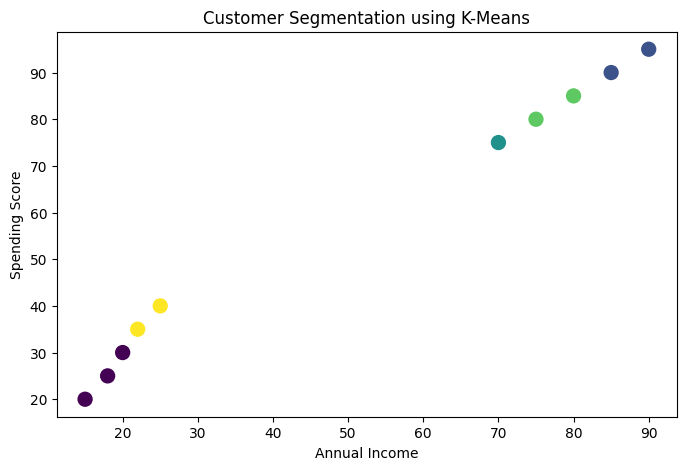

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Income'],
    df['Spending_Score'],
    c=df['Cluster'],
    s=100
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")

plt.show()